# 00 — Pré-processamento

Prepara as bases do projeto antes de qualquer técnica de mineração. A unidade de análise é o **município** de ES, MG e SP.

| Base | Fonte | Arquivo bruto | Script de coleta |
| --- | --- | --- | --- |
| Clima (climatologia) | NASA POWER | `data/raw/clima_municipios.csv` | `scripts/coletar_clima_municipios.py` |
| Produção agrícola por município | IBGE / PAM | `data/raw/pam_culturas_municipios.csv` | `scripts/coletar_ibge_pam.py` |
| Localização dos municípios | `kelvins/municipios-brasileiros` | `data/raw/municipios_coord.csv` | (baixado pelo script de clima) |

Os arquivos de `data/raw/` não são alterados. O resultado vai para `data/processed/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

clima = pd.read_csv('../data/raw/clima_municipios.csv')
pam = pd.read_csv('../data/raw/pam_culturas_municipios.csv')
mun = pd.read_csv('../data/raw/municipios_coord.csv')

print('clima     :', clima.shape)
print('PAM       :', pam.shape)
print('municípios:', mun.shape)
pam.head()

clima     : (1576, 11)
PAM       : (152797, 8)
municípios: (5571, 9)


,cod,municipio,uf,cultura,ano,area_colhida_ha,producao_t,rendimento_kg_ha
0,3100104,Abadia dos Dourados,MG,Café,2001,90.0,154.0,1711.0
1,3100104,Abadia dos Dourados,MG,Café,2002,76.0,60.0,789.0
2,3100104,Abadia dos Dourados,MG,Café,2003,96.0,75.0,781.0
3,3100104,Abadia dos Dourados,MG,Café,2004,96.0,86.0,895.0
4,3100104,Abadia dos Dourados,MG,Café,2005,74.0,98.0,1324.0


## 1. Seleção de colunas

- **Municípios:** só os de ES, MG e SP, com `cod`, `municipio`, `uf`, `latitude` e `longitude`. Ficam de fora capital, DDD, fuso e código SIAFI.
- **PAM:** `cod`, `uf`, `cultura`, `ano`, área colhida, produção e rendimento.
- **Clima:** as 10 variáveis da climatologia da NASA POWER.

In [2]:
UFS = {31: 'MG', 32: 'ES', 35: 'SP'}
mun_antes = mun.shape
mun = mun[mun['codigo_uf'].isin(UFS)].copy()
mun['uf'] = mun['codigo_uf'].map(UFS)
mun = mun.rename(columns={'codigo_ibge': 'cod', 'nome': 'municipio'})[['cod', 'municipio', 'uf', 'latitude', 'longitude']]
print('municípios:', mun_antes, '->', mun.shape)

pam = pam[['cod', 'uf', 'cultura', 'ano', 'area_colhida_ha', 'producao_t', 'rendimento_kg_ha']]
print('PAM colunas:', pam.shape[1], '| culturas:', sorted(pam['cultura'].unique()))

municípios: (5571, 9) -> (1576, 5)
PAM colunas: 7 | culturas: ['Café', 'Cana-de-açúcar', 'Feijão', 'Laranja', 'Milho', 'Soja']


## 2. Valores nulos

In [3]:
print('Nulos no clima:', int(clima.isna().sum().sum()))
print('Nulos na PAM:'); print(pam.isna().sum())
print('Nulos nos municípios:', int(mun.isna().sum().sum()))

Nulos no clima: 0
Nulos na PAM:
cod                  0
uf                   0
cultura              0
ano                  0
area_colhida_ha      0
producao_t           0
rendimento_kg_ha    11
dtype: int64
Nulos nos municípios: 0


O clima não tem nulos. Na PAM, só `rendimento_kg_ha` tem poucos vazios (linhas em que a área ou a produção é zero, então não há rendimento a calcular). Como o rendimento é só `produção / área` e não é usado como rótulo, essas linhas são mantidas.

In [4]:
falta_rend = pam['rendimento_kg_ha'].isna() & pam['producao_t'].notna() & (pam['area_colhida_ha'] > 0)
pam.loc[falta_rend, 'rendimento_kg_ha'] = pam.loc[falta_rend, 'producao_t'] * 1000 / pam.loc[falta_rend, 'area_colhida_ha']
print('Rendimentos recalculados:', int(falta_rend.sum()))
print('Nulos restantes na PAM:'); print(pam.isna().sum())

Rendimentos recalculados: 0
Nulos restantes na PAM:
cod                  0
uf                   0
cultura              0
ano                  0
area_colhida_ha      0
producao_t           0
rendimento_kg_ha    11
dtype: int64


## 3. Duplicados

In [5]:
print('Duplicados no clima (cod):', int(clima.duplicated('cod').sum()))
print('Duplicados nos municípios (cod):', int(mun.duplicated('cod').sum()))
print('Duplicados na PAM (cod + cultura + ano):', int(pam.duplicated(['cod', 'cultura', 'ano']).sum()))
clima = clima.drop_duplicates('cod'); mun = mun.drop_duplicates('cod')
pam = pam.drop_duplicates(['cod', 'cultura', 'ano'])

Duplicados no clima (cod): 0
Duplicados nos municípios (cod): 0
Duplicados na PAM (cod + cultura + ano): 0


## 4. Inconsistências (regras de domínio)

- Clima: umidade entre 0 e 100, chuva ≥ 0, radiação ≥ 0, temperatura mínima ≤ temperatura média.
- PAM: área, produção e rendimento ≥ 0 e, quando há área e produção, rendimento coerente com `produção / área` (tolerância de 5%).

In [6]:
regra_clima = (
    (clima['umidade'] < 0) | (clima['umidade'] > 100) | (clima['chuva_mm_dia'] < 0) |
    (clima['radiacao'] < 0) | (clima['temp_min'] > clima['temp_media'])
)
neg = (pam[['area_colhida_ha', 'producao_t', 'rendimento_kg_ha']] < 0).any(axis=1)
calc = pam['producao_t'] * 1000 / pam['area_colhida_ha'].replace(0, np.nan)
incoerente = (pam['rendimento_kg_ha'] - calc).abs() / calc > 0.05
print('Clima com violação de regra:', int(regra_clima.sum()))
print('PAM com valor negativo:', int(neg.sum()))
print('PAM com rendimento incoerente (>5%):', int(incoerente.sum()), 'de', len(pam))
clima = clima[~regra_clima]; pam = pam[~neg]

Clima com violação de regra: 0
PAM com valor negativo: 0
PAM com rendimento incoerente (>5%): 0 de 152797


Nenhuma linha violou as regras. O rótulo do modelo usa só a **área colhida**.

## 5. Outliers (IQR)

São **contados e visualizados, mas não removidos**: municípios com área muito grande de uma cultura são casos reais (por exemplo, as maiores regiões produtoras).

              outliers  percentual
temp_media           0        0.00
temp_min            20        1.27
chuva_mm_dia       128        8.12
umidade             26        1.65
radiacao            12        0.76

Outliers de área colhida (IQR) por cultura:


                outliers  linhas_com_area
cultura                                  
Café                3361            24446
Cana-de-açúcar      3743            30466
Feijão              2956            28671
Laranja             3612            21078
Milho               4256            35527
Soja                1808            12598


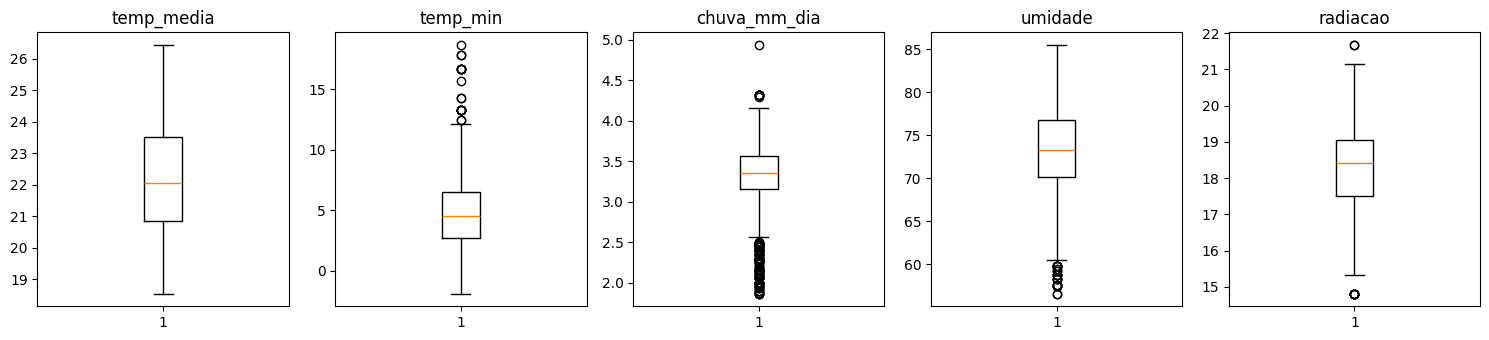

In [7]:
def contar_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

vars_clima = ['temp_media', 'temp_min', 'chuva_mm_dia', 'umidade', 'radiacao']
res = pd.DataFrame({'outliers': {v: contar_outliers(clima[v]) for v in vars_clima}})
res['percentual'] = (res['outliers'] / len(clima) * 100).round(2)
print(res)
area_pos = pam.loc[pam['area_colhida_ha'] > 0]
print('\nOutliers de área colhida (IQR) por cultura:')
print(area_pos.groupby('cultura')['area_colhida_ha'].apply(contar_outliers).to_frame('outliers').join(
    area_pos.groupby('cultura')['area_colhida_ha'].size().rename('linhas_com_area')))

fig, eixos = plt.subplots(1, 5, figsize=(15, 3.5))
for ax, v in zip(eixos, vars_clima):
    ax.boxplot(clima[v]); ax.set_title(v)
plt.tight_layout(); plt.savefig('../data/processed/boxplot_clima.png', bbox_inches='tight'); plt.show()

## 6. Novas variáveis

**Clima:**
- `chuva_anual` = chuva média diária × 365,25 (mm/ano);
- `amplitude_termica` = temperatura de janeiro − temperatura de julho (sazonalidade);
- `contraste_chuva` = chuva do verão − chuva da seca (sazonalidade da chuva).

**Culturas** (rótulos do modelo): para cada município e cultura, a **área colhida média de 2015 a 2024**. O município é considerado **apto** para a cultura quando essa média é de pelo menos `LIMITE_HA` hectares. Sem registro no IBGE, a área é 0. Também se calcula a **cultura dominante** (a de maior área entre as seis, desde que apta).

In [8]:
clima['chuva_anual'] = clima['chuva_mm_dia'] * 365.25
clima['amplitude_termica'] = clima['temp_jan'] - clima['temp_jul']
clima['contraste_chuva'] = clima['chuva_verao'] - clima['chuva_seca']

LIMITE_HA = 500
ANO_INI, ANO_FIM = 2015, 2024
area = (pam[pam['ano'].between(ANO_INI, ANO_FIM)]
        .groupby(['cod', 'cultura'])['area_colhida_ha'].mean().unstack().fillna(0))
culturas = ['Café', 'Cana-de-açúcar', 'Feijão', 'Laranja', 'Milho', 'Soja']
area = area.reindex(columns=culturas).fillna(0)
area.columns = ['area_' + c for c in culturas]

dados = mun.merge(clima, on='cod', how='inner').merge(area, left_on='cod', right_index=True, how='left')
cols_area = ['area_' + c for c in culturas]
dados[cols_area] = dados[cols_area].fillna(0)
for c in culturas:
    dados['apto_' + c] = (dados['area_' + c] >= LIMITE_HA).astype(int)

maior = dados[cols_area].idxmax(axis=1).str.replace('area_', '', regex=False)
dados['cultura_dominante'] = np.where(dados[cols_area].max(axis=1) >= LIMITE_HA, maior, 'Nenhuma')
print(dados.shape)
print(dados[['apto_' + c for c in culturas]].sum().rename('municípios aptos'))
print(dados['cultura_dominante'].value_counts())

(1576, 31)
apto_Café              369
apto_Cana-de-açúcar    556
apto_Feijão            170
apto_Laranja           161
apto_Milho             558
apto_Soja              453
Name: municípios aptos, dtype: int64
cultura_dominante
Nenhuma           582
Cana-de-açúcar    446
Café              277
Milho             132
Soja              109
Laranja            18
Feijão             12
Name: count, dtype: int64


## 7. Município por município: cobertura

In [9]:
print('Municípios:', len(mun), '| com clima:', dados.shape[0])
print('Municípios sem nenhum registro de cultura na PAM:', int((dados[cols_area].sum(axis=1) == 0).sum()))
print('Municípios por UF:'); print(dados['uf'].value_counts())

Municípios: 1576 | com clima: 1576
Municípios sem nenhum registro de cultura na PAM: 54
Municípios por UF:
uf
MG    853
SP    645
ES     78
Name: count, dtype: int64


## 8. Salvar

In [10]:
clima_saida = dados[['cod', 'municipio', 'uf', 'latitude', 'longitude'] + [c for c in clima.columns if c != 'cod']]
clima_saida.to_csv('../data/processed/clima_municipios_limpo.csv', index=False)
pam_saida = pam.merge(mun[['cod', 'municipio']], on='cod', how='inner')
pam_saida.to_csv('../data/processed/pam_limpo.csv', index=False)
dados.to_csv('../data/processed/dataset_municipios.csv', index=False)
print('clima_municipios_limpo', clima_saida.shape)
print('pam_limpo             ', pam_saida.shape)
print('dataset_municipios    ', dados.shape)

clima_municipios_limpo (1576, 18)
pam_limpo              (152797, 8)
dataset_municipios     (1576, 31)
